# 13 — Target relativo ao prazo: baseline, regressão e survival

## Objetivo

Este notebook organiza a comparação em três etapas simples:

1. **Baseline:** uma referência mínima, sem tentar aprender relações complexas.
2. **Regressão:** um modelo supervisionado tradicional, treinado somente com contratos concluídos.
3. **Survival/AFT:** um modelo que usa contratos concluídos **e** contratos ainda em andamento como observações censuradas.

A pergunta principal é:

> **Quanto tempo a obra tende a consumir em relação ao prazo original?**

Em vez de modelar diretamente `dias de atraso`, usamos um target relativo:

`tempo_relativo = duração_observada / prazo_original`

Isso reduz o efeito mecânico de contratos naturalmente mais longos e cria uma escala comparável entre obras.

---

## Por que usar o prazo original como denominador?

O prazo original é conhecido no início e não muda. Isso é importante para o modelo de sobrevivência.

Se dividíssemos a duração pelo prazo vigente, o próprio denominador poderia mudar ao longo da obra por causa de aditivos. O target deixaria de estar em uma escala fixa.

Por isso:

- o **target survival** é normalizado pelo prazo original;
- o **prazo vigente atual** entra depois como um **limite de comparação**.

Exemplo:

- `tempo_relativo = 1,30` significa que a obra consumiu 130% do prazo original;
- se o prazo vigente atual equivale a `1,50 × prazo_original`, então o contrato ainda pode estar dentro do prazo contratual vigente.

Essa separação permite usar o modelo tanto no início quanto durante a execução.

In [5]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize
from scipy.stats import norm

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import GammaRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 180)

DATA_CORTE = pd.Timestamp("2026-10-14")

OUTPUT_DIR = Path(
    "/mnt/data/13_target_relativo_outputs"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("Data de corte:", DATA_CORTE.date())
print("Saídas:", OUTPUT_DIR)

Data de corte: 2026-10-14
Saídas: \mnt\data\13_target_relativo_outputs


# Etapa 1 — Preparação do dataset

## 1. Carregar a base de contratos

Para esta comparação, usamos somente informações essenciais da tabela de contratos.

A feature inicial do modelo será deliberadamente simples:

- `prazo_original_dias`

Isso evita depender, neste momento, de variáveis de execução cujo histórico temporal ainda precisa ser consolidado.

In [6]:
def pastas_raw_candidatas():
    atual = Path.cwd().resolve()
    candidatas = [
        raiz / "data" / "raw"
        for raiz in (atual, *atual.parents)
    ]
    candidatas.append(Path("/mnt/data/raw"))
    return candidatas

def localizar(*nomes):
    pastas = pastas_raw_candidatas()
    for pasta in pastas:
        for nome in nomes:
            caminho = pasta / nome
            if caminho.is_file():
                return caminho.resolve()
    raise FileNotFoundError(
        f"Arquivo(s) não encontrado(s): {', '.join(nomes)}. "
        f"Diretório atual: {Path.cwd().resolve()}. "
        f"Pastas verificadas: {', '.join(str(p) for p in pastas)}"
    )


PATH_CONTRATOS = localizar(
    "contratos_com_conclusao_andamento.csv"
)

contratos = pd.read_csv(
    PATH_CONTRATOS,
    encoding="utf-8-sig",
    low_memory=False,
)

print("Shape:", contratos.shape)
print()
print("Colunas:")
print(contratos.columns.tolist())

Shape: (64, 10)

Colunas:
['id_contrato', 'classificacao_contrato', 'data_os', 'data_termino_original', 'data_termino_vigente_final', 'data_conclusao_definitiva', 'status_final_controle', 'prazo_original_dias', 'diferenca_vigente_original_dias', 'atraso_definitivo_dias']


## 2. Padronizar datas e criar os três grupos

Mantemos os 64 contratos.

Cada contrato é classificado como:

- `CONCLUIDO_COM_TARGET`
- `EM_ANDAMENTO_CENSURADO`
- `SUSPENSO_PARALISADO`

Se existe conclusão definitiva e atraso definitivo preenchido, o contrato é tratado como concluído mesmo que o status cadastral ainda esteja desatualizado.

In [7]:
df = contratos.copy()

for coluna in [
    "data_os",
    "data_termino_original",
    "data_termino_vigente_final",
    "data_conclusao_definitiva",
]:
    df[coluna] = pd.to_datetime(
        df[coluna],
        errors="coerce",
    )


tem_target = (
    df["data_conclusao_definitiva"].notna()
    & df["atraso_definitivo_dias"].notna()
)

status_suspenso = (
    df["status_final_controle"]
    .astype(str)
    .str.upper()
    .str.contains(
        "SUSPENSO|PARALISADO",
        regex=True,
    )
)


df["grupo_modelagem"] = np.select(
    [
        tem_target,
        status_suspenso,
    ],
    [
        "CONCLUIDO_COM_TARGET",
        "SUSPENSO_PARALISADO",
    ],
    default="EM_ANDAMENTO_CENSURADO",
)


resumo_grupos = (
    df["grupo_modelagem"]
    .value_counts()
    .rename_axis("grupo")
    .reset_index(name="contratos")
)

display(resumo_grupos)

assert len(df) == 64

,grupo,contratos
0,CONCLUIDO_COM_TARGET,50
1,EM_ANDAMENTO_CENSURADO,13
2,SUSPENSO_PARALISADO,1


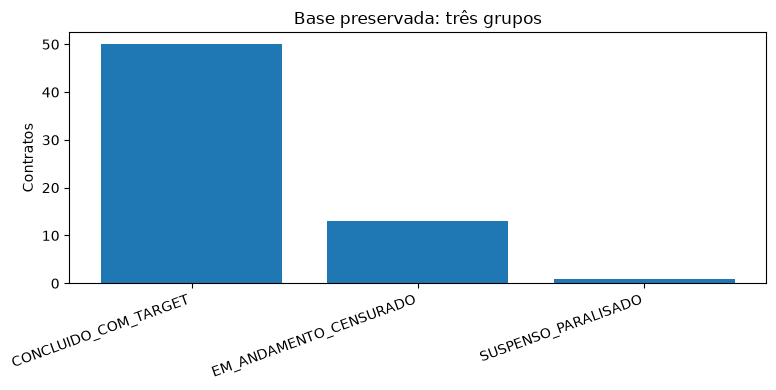

In [8]:
plt.figure(figsize=(8, 4))

plt.bar(
    resumo_grupos["grupo"],
    resumo_grupos["contratos"],
)

plt.ylabel("Contratos")
plt.title("Base preservada: três grupos")

plt.xticks(
    rotation=20,
    ha="right",
)

plt.tight_layout()
plt.show()

## 3. Construir o target relativo

Para contratos concluídos:

`tempo_observado = data_conclusão - data_OS`

Para contratos censurados:

`tempo_observado = data_corte - data_OS`

Depois:

`tempo_relativo_observado = tempo_observado / prazo_original`

O indicador `evento_conclusao` informa ao modelo se aquele tempo terminou em uma conclusão observada (`1`) ou se ainda está censurado (`0`).

O contrato suspenso/paralisado permanece no dataset, mas não entra no ajuste principal.

In [9]:
df["evento_conclusao"] = (
    df["grupo_modelagem"]
    .eq("CONCLUIDO_COM_TARGET")
    .astype(int)
)


df["data_fim_observacao"] = (
    df["data_conclusao_definitiva"]
    .where(
        df["evento_conclusao"].eq(1),
        DATA_CORTE,
    )
)


df["tempo_observado_dias"] = (
    df["data_fim_observacao"]
    - df["data_os"]
).dt.days.clip(lower=1)


df["tempo_relativo_observado"] = (
    df["tempo_observado_dias"]
    / df["prazo_original_dias"]
)


df["flag_apto_modelagem"] = (
    ~df["grupo_modelagem"]
    .eq("SUSPENSO_PARALISADO")
).astype(int)


# Feature inicial simples e estável.
df["log_prazo_original"] = np.log1p(
    df["prazo_original_dias"]
)


assert (
    df.loc[
        df["flag_apto_modelagem"].eq(1),
        "prazo_original_dias",
    ] > 0
).all()


display(
    df[
        [
            "id_contrato",
            "grupo_modelagem",
            "prazo_original_dias",
            "tempo_observado_dias",
            "tempo_relativo_observado",
            "evento_conclusao",
        ]
    ].head(10)
)

,id_contrato,grupo_modelagem,prazo_original_dias,tempo_observado_dias,tempo_relativo_observado,evento_conclusao
0,11,CONCLUIDO_COM_TARGET,150,175,1.166667,1
1,12,CONCLUIDO_COM_TARGET,90,229,2.544444,1
2,18,CONCLUIDO_COM_TARGET,120,150,1.250000,1
3,29,CONCLUIDO_COM_TARGET,240,524,2.183333,1
4,30,CONCLUIDO_COM_TARGET,90,90,1.000000,1
5,31,CONCLUIDO_COM_TARGET,120,210,1.750000,1
6,32,CONCLUIDO_COM_TARGET,90,150,1.666667,1
7,33,CONCLUIDO_COM_TARGET,660,750,1.136364,1
8,46,CONCLUIDO_COM_TARGET,180,298,1.655556,1
9,47,CONCLUIDO_COM_TARGET,180,222,1.233333,1


## 4. Prazo vigente como limite operacional

O target permanece em uma escala fixa baseada no prazo original.

Para avaliar o risco **hoje**, calculamos o prazo vigente atual em relação ao prazo original:

`limite_relativo_vigente = prazo_vigente_atual / prazo_original`

Assim:

- no início, o limite é aproximadamente `1`;
- após um aditivo de prazo, o limite pode ser maior que `1`.

O modelo estima uma distribuição para o tempo relativo. O prazo vigente apenas define onde colocamos a linha de corte.

In [10]:
df["prazo_vigente_atual_dias"] = (
    df["data_termino_vigente_final"]
    - df["data_os"]
).dt.days


# Se o prazo vigente estiver ausente, usamos o prazo original.
df["prazo_vigente_atual_dias"] = (
    df["prazo_vigente_atual_dias"]
    .where(
        df["prazo_vigente_atual_dias"] > 0,
        df["prazo_original_dias"],
    )
)


df["limite_relativo_vigente"] = (
    df["prazo_vigente_atual_dias"]
    / df["prazo_original_dias"]
)


display(
    df[
        [
            "id_contrato",
            "prazo_original_dias",
            "prazo_vigente_atual_dias",
            "limite_relativo_vigente",
        ]
    ].head()
)

,id_contrato,prazo_original_dias,prazo_vigente_atual_dias,limite_relativo_vigente
0,11,150,150.0,1.000000
1,12,90,90.0,1.000000
2,18,120,150.0,1.250000
3,29,240,418.0,1.741667
4,30,90,90.0,1.000000


## 5. Como ficou o target nos contratos concluídos

count    50.000000
mean      1.726609
std       1.030391
min       0.555556
25%       1.158854
50%       1.440972
75%       1.902778
max       7.333333
Name: tempo_relativo_observado, dtype: float64


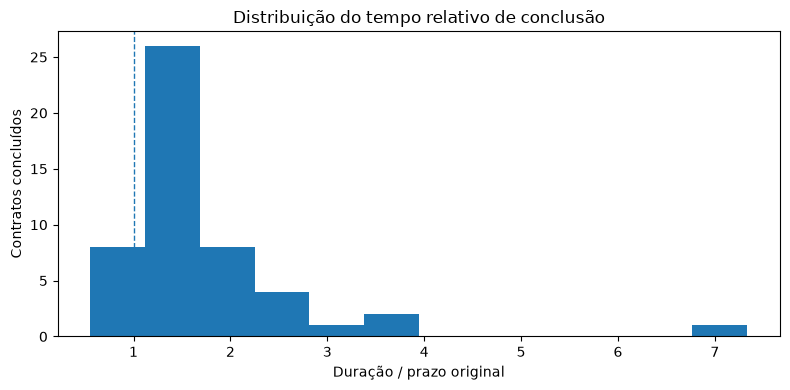

In [11]:
concluidos = df[
    df["evento_conclusao"].eq(1)
].copy()

print(
    concluidos[
        "tempo_relativo_observado"
    ].describe()
)

plt.figure(figsize=(8, 4))

plt.hist(
    concluidos[
        "tempo_relativo_observado"
    ],
    bins=12,
)

plt.axvline(
    1.0,
    linewidth=1,
    linestyle="--",
)

plt.xlabel(
    "Duração / prazo original"
)

plt.ylabel(
    "Contratos concluídos"
)

plt.title(
    "Distribuição do tempo relativo de conclusão"
)

plt.tight_layout()
plt.show()

# Etapa 2 — Validação temporal

## 6. Regra de validação

A validação precisa reproduzir o que seria conhecido em cada momento histórico.

Para cada fold:

1. escolhemos uma data de corte;
2. contratos que já haviam concluído até aquela data entram como eventos;
3. contratos que ainda estavam abertos naquela data entram como censurados;
4. os contratos iniciados depois formam a validação.

Isso evita usar uma conclusão futura dentro do treino.

Para comparar os três modelos em uma métrica comum, o erro de previsão é calculado apenas nos contratos da validação que hoje já possuem conclusão conhecida.

In [12]:
model_data = (
    df[
        df["flag_apto_modelagem"].eq(1)
    ]
    .sort_values(
        [
            "data_os",
            "id_contrato",
        ]
    )
    .reset_index(drop=True)
)


def construir_treino_historico(
    base,
    cutoff,
):

    train = base[
        base["data_os"] <= cutoff
    ].copy()

    evento_ate_cutoff = (
        train[
            "data_conclusao_definitiva"
        ].notna()
        & (
            train[
                "data_conclusao_definitiva"
            ] <= cutoff
        )
    )

    train["evento_fold"] = (
        evento_ate_cutoff.astype(int)
    )

    train["fim_fold"] = (
        train[
            "data_conclusao_definitiva"
        ]
        .where(
            evento_ate_cutoff,
            cutoff,
        )
    )

    train["tempo_fold_dias"] = (
        train["fim_fold"]
        - train["data_os"]
    ).dt.days.clip(lower=1)

    train["tempo_rel_fold"] = (
        train["tempo_fold_dias"]
        / train["prazo_original_dias"]
    )

    return train


FOLD_STARTS = [
    28,
    35,
    42,
    49,
]

folds = []

for start in FOLD_STARTS:

    val = (
        model_data
        .iloc[
            start:start + 7
        ]
        .copy()
    )

    if len(val) < 5:
        continue

    cutoff = (
        val["data_os"].min()
        - pd.Timedelta(days=1)
    )

    train = construir_treino_historico(
        model_data.iloc[:start].copy(),
        cutoff,
    )

    folds.append({
        "cutoff": cutoff,
        "train": train,
        "val": val,
    })


resumo_folds = pd.DataFrame([
    {
        "fold": i,
        "cutoff": f["cutoff"],
        "treino_total": len(f["train"]),
        "eventos_treino": int(
            f["train"]["evento_fold"].sum()
        ),
        "censurados_treino": int(
            f["train"]["evento_fold"].eq(0).sum()
        ),
        "validacao_total": len(f["val"]),
        "concluidos_validacao": int(
            f["val"]["evento_conclusao"].sum()
        ),
    }
    for i, f in enumerate(
        folds,
        start=1,
    )
])

display(resumo_folds)

,fold,cutoff,treino_total,eventos_treino,censurados_treino,validacao_total,concluidos_validacao
0,1,2022-08-15,28,23,5,7,7
1,2,2023-11-20,35,28,7,7,6
2,3,2024-05-19,42,31,11,7,5
3,4,2025-04-28,49,41,8,7,4


# Etapa 3 — Modelo baseline

## 7. Baseline: mediana do tempo relativo

O baseline não usa nenhuma feature.

Ele simplesmente prevê, em cada fold, a mediana de:

`duração / prazo_original`

dos contratos que já estavam concluídos no treino.

Esse modelo responde:

> "Sem aprender relações específicas, qual é a duração relativa típica?"

Qualquer modelo mais sofisticado deve superar essa referência.

In [13]:
def harrell_c_index(
    tempo,
    evento,
    risco,
):
    tempo = np.asarray(
        tempo,
        dtype=float,
    )

    evento = np.asarray(
        evento,
        dtype=int,
    )

    risco = np.asarray(
        risco,
        dtype=float,
    )

    concordantes = 0.0
    empates = 0.0
    comparaveis = 0.0

    for i in range(len(tempo)):

        for j in range(
            i + 1,
            len(tempo),
        ):

            if (
                tempo[i] < tempo[j]
                and evento[i] == 1
            ):

                comparaveis += 1

                if risco[i] > risco[j]:
                    concordantes += 1

                elif risco[i] == risco[j]:
                    empates += 1

            elif (
                tempo[j] < tempo[i]
                and evento[j] == 1
            ):

                comparaveis += 1

                if risco[j] > risco[i]:
                    concordantes += 1

                elif risco[i] == risco[j]:
                    empates += 1

    if comparaveis == 0:
        return np.nan

    return (
        concordantes
        + 0.5 * empates
    ) / comparaveis


def calcular_metricas(
    validacao,
    pred_relativo,
):

    y_rel = (
        validacao[
            "tempo_relativo_observado"
        ].to_numpy()
    )

    prazo = (
        validacao[
            "prazo_original_dias"
        ].to_numpy()
    )

    y_duracao = (
        validacao[
            "tempo_observado_dias"
        ].to_numpy()
    )

    pred_relativo = np.asarray(
        pred_relativo,
        dtype=float,
    )

    pred_duracao = (
        pred_relativo * prazo
    )

    atraso_original_real = np.maximum(
        0,
        y_duracao - prazo,
    )

    atraso_original_pred = np.maximum(
        0,
        pred_duracao - prazo,
    )

    return {
        "mae_relativo": mean_absolute_error(
            y_rel,
            pred_relativo,
        ),

        "rmse_relativo": np.sqrt(
            mean_squared_error(
                y_rel,
                pred_relativo,
            )
        ),

        # Métrica principal:
        # erro na duração prevista, em dias.
        "mae_duracao_dias": mean_absolute_error(
            y_duracao,
            pred_duracao,
        ),

        # Métrica de negócio auxiliar:
        # erro no estouro do prazo ORIGINAL.
        "mae_estouro_original_dias": (
            mean_absolute_error(
                atraso_original_real,
                atraso_original_pred,
            )
        ),

        "cindex": harrell_c_index(
            y_rel,
            np.ones(
                len(validacao),
                dtype=int,
            ),
            -pred_relativo,
        ),
    }

In [14]:
baseline_rows = []

for fold_id, fold in enumerate(
    folds,
    start=1,
):

    train = fold["train"]

    val_event = (
        fold["val"][
            fold["val"][
                "evento_conclusao"
            ].eq(1)
        ]
        .copy()
    )

    train_event = train[
        train["evento_fold"].eq(1)
    ].copy()

    mediana_relativa = (
        train_event[
            "tempo_rel_fold"
        ].median()
    )

    pred = np.full(
        len(val_event),
        mediana_relativa,
    )

    baseline_rows.append({
        "fold": fold_id,
        "modelo": "Baseline mediana",
        "alpha": np.nan,
        "eventos_treino": len(
            train_event
        ),
        "concluidos_validacao": len(
            val_event
        ),
        **calcular_metricas(
            val_event,
            pred,
        ),
    })


baseline_cv = pd.DataFrame(
    baseline_rows
)

display(
    baseline_cv.round(3)
)

,fold,modelo,alpha,eventos_treino,concluidos_validacao,mae_relativo,rmse_relativo,mae_duracao_dias,mae_estouro_original_dias,cindex
0,1,Baseline mediana,NaN,23,7,0.391,0.446,101.571,101.571,0.5
1,2,Baseline mediana,NaN,28,6,0.308,0.371,70.125,70.125,0.5
2,3,Baseline mediana,NaN,31,5,0.756,0.991,117.600,109.600,0.5
3,4,Baseline mediana,NaN,41,4,1.141,1.350,138.052,137.802,0.5


# Etapa 4 — Modelo de regressão

## 8. GammaRegressor

O target `tempo_relativo` é:

- contínuo;
- estritamente positivo;
- assimétrico.

Por isso, um `GammaRegressor` é mais adequado do que uma regressão linear simples.

Limitação importante:

> a regressão só consegue treinar com contratos cujo desfecho já era conhecido.

Os contratos censurados não entram no ajuste da regressão.

In [15]:
FEATURES = [
    "log_prazo_original",
]


def criar_preprocessador():

    return ColumnTransformer([
        (
            "num",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="median",
                    ),
                ),
                (
                    "scaler",
                    StandardScaler(),
                ),
            ]),
            FEATURES,
        )
    ])


ALPHAS_GAMMA = [
    0.1,
    1.0,
    10.0,
    100.0,
]


gamma_rows = []


for fold_id, fold in enumerate(
    folds,
    start=1,
):

    train_event = (
        fold["train"][
            fold["train"][
                "evento_fold"
            ].eq(1)
        ]
        .copy()
    )

    val_event = (
        fold["val"][
            fold["val"][
                "evento_conclusao"
            ].eq(1)
        ]
        .copy()
    )

    for alpha in ALPHAS_GAMMA:

        prep = criar_preprocessador()

        X_train = prep.fit_transform(
            train_event[FEATURES]
        )

        X_val = prep.transform(
            val_event[FEATURES]
        )

        modelo = GammaRegressor(
            alpha=alpha,
            max_iter=5000,
        )

        modelo.fit(
            X_train,
            train_event[
                "tempo_rel_fold"
            ],
        )

        pred = modelo.predict(
            X_val
        )

        gamma_rows.append({
            "fold": fold_id,
            "modelo": "GammaRegressor",
            "alpha": alpha,
            "eventos_treino": len(
                train_event
            ),
            "concluidos_validacao": len(
                val_event
            ),
            **calcular_metricas(
                val_event,
                pred,
            ),
        })


gamma_cv = pd.DataFrame(
    gamma_rows
)

display(
    gamma_cv.round(3)
)

,fold,modelo,alpha,eventos_treino,concluidos_validacao,mae_relativo,rmse_relativo,mae_duracao_dias,mae_estouro_original_dias,cindex
0,1,GammaRegressor,0.1,23,7,0.290,0.348,56.304,52.948,0.738
1,1,GammaRegressor,1.0,23,7,0.234,0.286,48.451,48.451,0.738
2,1,GammaRegressor,10.0,23,7,0.347,0.405,136.332,136.332,0.738
3,1,GammaRegressor,100.0,23,7,0.377,0.453,158.269,158.269,0.738
4,2,GammaRegressor,0.1,28,6,0.558,0.617,60.870,60.870,0.800
5,2,GammaRegressor,1.0,28,6,0.524,0.556,77.519,77.519,0.800
6,2,GammaRegressor,10.0,28,6,0.512,0.548,102.902,102.902,0.800
7,2,GammaRegressor,100.0,28,6,0.512,0.556,109.195,109.195,0.800
8,3,GammaRegressor,0.1,31,5,0.762,0.986,107.333,99.333,0.500
9,3,GammaRegressor,1.0,31,5,0.787,0.987,118.480,110.480,0.500


# Etapa 5 — Modelo survival

## 9. AFT Log-Normal no tempo relativo

O AFT usa o mesmo target relativo, mas tem uma vantagem decisiva:

- contratos concluídos entram como eventos;
- contratos ainda abertos entram como censurados.

Assim, ele aproveita mais informação do que a regressão tradicional.

O modelo continua simples: apenas `log_prazo_original` como feature inicial.

In [16]:
class LogNormalAFT:

    def __init__(
        self,
        alpha=1.0,
    ):
        self.alpha = alpha


    def fit(
        self,
        X,
        tempo,
        evento,
    ):

        X = np.asarray(
            X,
            dtype=float,
        )

        tempo = np.asarray(
            tempo,
            dtype=float,
        )

        evento = np.asarray(
            evento,
            dtype=int,
        )

        y = np.log(
            np.maximum(
                tempo,
                1e-8,
            )
        )

        X1 = np.column_stack([
            np.ones(len(X)),
            X,
        ])

        p = X1.shape[1]

        inicial = np.zeros(
            p + 1
        )

        inicial[0] = np.median(
            y
        )

        inicial[-1] = np.log(
            np.std(y) + 1e-3
        )


        def objetivo(theta):

            beta = theta[:p]

            sigma = np.exp(
                theta[p]
            )

            z = (
                y
                - X1 @ beta
            ) / sigma

            loglik = np.where(
                evento == 1,

                norm.logpdf(z)
                - np.log(sigma)
                - y,

                norm.logsf(z),
            )

            penalizacao = (
                0.5
                * self.alpha
                * np.sum(
                    beta[1:] ** 2
                )
            )

            return (
                -np.sum(loglik)
                + penalizacao
            )


        self.resultado_ = minimize(
            objetivo,
            inicial,
            method="L-BFGS-B",
            bounds=(
                [(None, None)] * p
                + [(-5, 3)]
            ),
        )

        self.beta_ = (
            self.resultado_.x[:p]
        )

        self.sigma_ = np.exp(
            self.resultado_.x[p]
        )

        return self


    def mu(
        self,
        X,
    ):

        X = np.asarray(
            X,
            dtype=float,
        )

        X1 = np.column_stack([
            np.ones(len(X)),
            X,
        ])

        return (
            X1 @ self.beta_
        )


    def mediana_tempo_relativo(
        self,
        X,
    ):

        return np.exp(
            self.mu(X)
        )


    def sobrevivencia(
        self,
        X,
        tempo_relativo,
    ):

        tempo_relativo = np.maximum(
            np.asarray(
                tempo_relativo,
                dtype=float,
            ),
            1e-8,
        )

        z = (
            np.log(
                tempo_relativo
            )
            - self.mu(X)
        ) / self.sigma_

        return norm.sf(z)


    def prob_exceder_limite_condicional(
        self,
        X,
        tempo_relativo_ja_observado,
        limite_relativo,
    ):
        # P(T > limite | T > tempo já observado)

        atual = np.asarray(
            tempo_relativo_ja_observado,
            dtype=float,
        )

        limite = np.asarray(
            limite_relativo,
            dtype=float,
        )

        s_atual = self.sobrevivencia(
            X,
            atual,
        )

        s_limite = self.sobrevivencia(
            X,
            limite,
        )

        prob = (
            s_limite
            / np.maximum(
                s_atual,
                1e-12,
            )
        )

        # Se já ultrapassou o limite e ainda não concluiu,
        # o estouro já está materializado.
        prob = np.where(
            limite <= atual,
            1.0,
            prob,
        )

        return np.clip(
            prob,
            0,
            1,
        )

In [17]:
ALPHAS_AFT = [
    0.1,
    1.0,
    10.0,
    100.0,
]


aft_rows = []


for fold_id, fold in enumerate(
    folds,
    start=1,
):

    train = fold["train"].copy()

    val_event = (
        fold["val"][
            fold["val"][
                "evento_conclusao"
            ].eq(1)
        ]
        .copy()
    )

    for alpha in ALPHAS_AFT:

        prep = criar_preprocessador()

        X_train = prep.fit_transform(
            train[FEATURES]
        )

        X_val = prep.transform(
            val_event[FEATURES]
        )

        modelo = LogNormalAFT(
            alpha=alpha
        )

        modelo.fit(
            X_train,
            train[
                "tempo_rel_fold"
            ],
            train[
                "evento_fold"
            ],
        )

        pred = (
            modelo
            .mediana_tempo_relativo(
                X_val
            )
        )

        aft_rows.append({
            "fold": fold_id,
            "modelo": "AFT Log-Normal",
            "alpha": alpha,
            "eventos_treino": int(
                train[
                    "evento_fold"
                ].sum()
            ),
            "censurados_treino": int(
                train[
                    "evento_fold"
                ].eq(0).sum()
            ),
            "concluidos_validacao": len(
                val_event
            ),
            **calcular_metricas(
                val_event,
                pred,
            ),
        })


aft_cv = pd.DataFrame(
    aft_rows
)

display(
    aft_cv.round(3)
)

,fold,modelo,alpha,eventos_treino,censurados_treino,concluidos_validacao,mae_relativo,rmse_relativo,mae_duracao_dias,mae_estouro_original_dias,cindex
0,1,AFT Log-Normal,0.1,23,5,7,0.191,0.283,26.223,26.223,0.738
1,1,AFT Log-Normal,1.0,23,5,7,0.190,0.283,25.610,25.610,0.738
2,1,AFT Log-Normal,10.0,23,5,7,0.186,0.283,24.911,24.911,0.738
3,1,AFT Log-Normal,100.0,23,5,7,0.239,0.316,62.827,62.827,0.738
4,2,AFT Log-Normal,0.1,28,7,6,0.411,0.454,52.657,52.657,0.800
5,2,AFT Log-Normal,1.0,28,7,6,0.411,0.454,52.785,52.785,0.800
6,2,AFT Log-Normal,10.0,28,7,6,0.407,0.449,54.018,54.018,0.800
7,2,AFT Log-Normal,100.0,28,7,6,0.387,0.425,62.588,62.588,0.800
8,3,AFT Log-Normal,0.1,31,11,5,0.745,0.978,108.144,100.144,0.500
9,3,AFT Log-Normal,1.0,31,11,5,0.745,0.978,108.178,100.178,0.500


# Etapa 6 — Comparação entre os modelos

## 10. Critério principal

Usaremos como métrica principal:

**MAE da duração prevista em dias**

Ela responde diretamente:

> Em média, quantos dias a duração prevista ficou distante da duração real?

Também mostramos:

- MAE do target relativo;
- MAE do estouro do prazo original;
- C-index, que mede capacidade de ordenação.

O melhor `alpha` de cada família é escolhido somente pela validação temporal.

In [18]:
todos_cv = pd.concat(
    [
        baseline_cv,
        gamma_cv,
        aft_cv,
    ],
    ignore_index=True,
)


resumo_modelos = (
    todos_cv
    .groupby(
        [
            "modelo",
            "alpha",
        ],
        dropna=False,
        as_index=False,
    )
    .agg(
        mae_duracao_dias=(
            "mae_duracao_dias",
            "mean",
        ),
        mae_duracao_dp=(
            "mae_duracao_dias",
            "std",
        ),
        mae_relativo=(
            "mae_relativo",
            "mean",
        ),
        mae_estouro_original_dias=(
            "mae_estouro_original_dias",
            "mean",
        ),
        cindex_medio=(
            "cindex",
            "mean",
        ),
        folds=(
            "fold",
            "count",
        ),
    )
)


# Melhor configuração de cada família.
melhor_por_familia = (
    resumo_modelos
    .sort_values(
        "mae_duracao_dias"
    )
    .groupby(
        "modelo",
        as_index=False,
    )
    .first()
    .sort_values(
        "mae_duracao_dias"
    )
    .reset_index(drop=True)
)


display(
    melhor_por_familia.round(3)
)

,modelo,alpha,mae_duracao_dias,mae_duracao_dp,mae_relativo,mae_estouro_original_dias,cindex_medio,folds
0,AFT Log-Normal,1.0,78.581,47.486,0.614,76.518,0.593,4
1,GammaRegressor,0.1,86.999,33.516,0.676,84.098,0.593,4
2,Baseline mediana,NaN,106.837,28.669,0.649,104.775,0.500,4


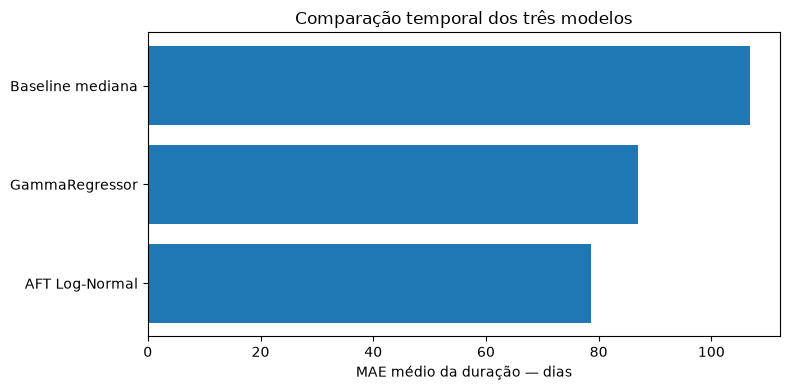

In [19]:
plt.figure(figsize=(8, 4))

plt.barh(
    melhor_por_familia[
        "modelo"
    ],
    melhor_por_familia[
        "mae_duracao_dias"
    ],
)

plt.xlabel(
    "MAE médio da duração — dias"
)

plt.title(
    "Comparação temporal dos três modelos"
)

plt.tight_layout()
plt.show()

## 11. Evolução por fold

Este gráfico é importante para evitar uma conclusão excessivamente otimista.

Se os erros aumentarem nos folds mais recentes, isso sugere mudança de perfil dos contratos ou pouca informação recente.

Nesse caso, mais contratos finalizados da coorte atual serão especialmente importantes para recalibrar o modelo.

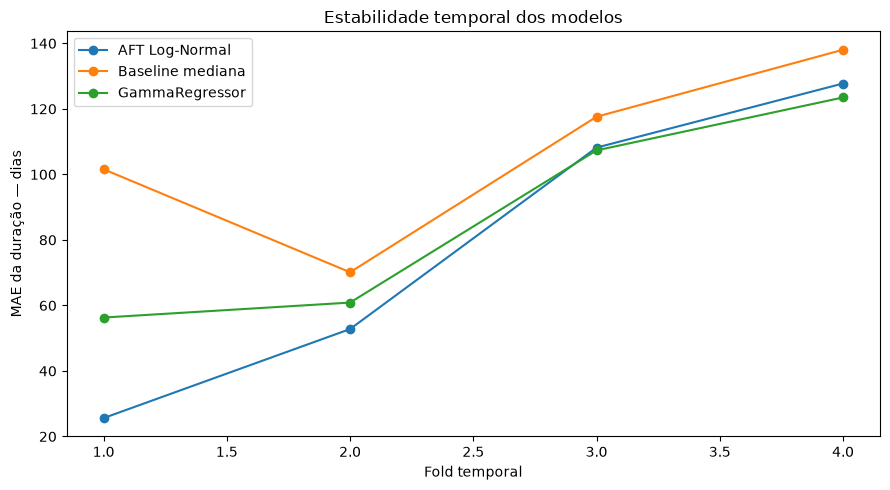

,fold,modelo,alpha,eventos_treino,concluidos_validacao,mae_duracao_dias,mae_relativo,cindex
0,1,Baseline mediana,NaN,23,7,101.571,0.391,0.500
1,2,Baseline mediana,NaN,28,6,70.125,0.308,0.500
2,3,Baseline mediana,NaN,31,5,117.600,0.756,0.500
3,4,Baseline mediana,NaN,41,4,138.052,1.141,0.500
4,1,GammaRegressor,0.1,23,7,56.304,0.290,0.738
8,2,GammaRegressor,0.1,28,6,60.870,0.558,0.800
12,3,GammaRegressor,0.1,31,5,107.333,0.762,0.500
16,4,GammaRegressor,0.1,41,4,123.489,1.094,0.333
21,1,AFT Log-Normal,1.0,23,7,25.610,0.190,0.738
25,2,AFT Log-Normal,1.0,28,6,52.785,0.411,0.800


In [20]:
melhores_params = {}

for modelo in [
    "Baseline mediana",
    "GammaRegressor",
    "AFT Log-Normal",
]:

    linha = (
        melhor_por_familia[
            melhor_por_familia[
                "modelo"
            ].eq(modelo)
        ]
        .iloc[0]
    )

    melhores_params[
        modelo
    ] = linha["alpha"]


comparacao_folds = []

for _, row in todos_cv.iterrows():

    modelo = row["modelo"]

    alpha_best = (
        melhores_params[
            modelo
        ]
    )

    if modelo == "Baseline mediana":
        ok = pd.isna(
            row["alpha"]
        )
    else:
        ok = np.isclose(
            row["alpha"],
            alpha_best,
        )

    if ok:
        comparacao_folds.append(
            row
        )


comparacao_folds = pd.DataFrame(
    comparacao_folds
)


plt.figure(figsize=(9, 5))

for modelo, parte in (
    comparacao_folds
    .groupby("modelo")
):

    parte = parte.sort_values(
        "fold"
    )

    plt.plot(
        parte["fold"],
        parte[
            "mae_duracao_dias"
        ],
        marker="o",
        label=modelo,
    )


plt.xlabel("Fold temporal")
plt.ylabel("MAE da duração — dias")
plt.title("Estabilidade temporal dos modelos")
plt.legend()
plt.tight_layout()
plt.show()


display(
    comparacao_folds[
        [
            "fold",
            "modelo",
            "alpha",
            "eventos_treino",
            "concluidos_validacao",
            "mae_duracao_dias",
            "mae_relativo",
            "cindex",
        ]
    ].round(3)
)

# Etapa 7 — Seleção do melhor modelo

O modelo final é escolhido automaticamente pelo menor **MAE médio da duração**.

Com uma base pequena, não devemos interpretar diferenças mínimas como definitivas. O objetivo é escolher uma referência aceitável e metodologicamente correta para continuar evoluindo.

In [21]:
melhor = (
    melhor_por_familia
    .sort_values(
        "mae_duracao_dias"
    )
    .iloc[0]
)


BEST_MODEL = (
    melhor["modelo"]
)

BEST_ALPHA = (
    melhor["alpha"]
)


print("Melhor modelo:", BEST_MODEL)

if pd.notna(BEST_ALPHA):
    print(
        "Melhor alpha:",
        float(BEST_ALPHA),
    )

print(
    "MAE médio da duração:",
    round(
        float(
            melhor[
                "mae_duracao_dias"
            ]
        ),
        2,
    ),
    "dias",
)

print(
    "MAE relativo:",
    round(
        float(
            melhor[
                "mae_relativo"
            ]
        ),
        3,
    ),
)

print(
    "C-index médio:",
    round(
        float(
            melhor[
                "cindex_medio"
            ]
        ),
        3,
    ),
)

Melhor modelo: AFT Log-Normal
Melhor alpha: 1.0
MAE médio da duração: 78.58 dias
MAE relativo: 0.614
C-index médio: 0.593


## 12. Quantificar o ganho sobre o baseline e sobre a regressão

In [22]:
def valor_modelo(
    modelo,
    coluna,
):

    return float(
        melhor_por_familia.loc[
            melhor_por_familia[
                "modelo"
            ].eq(modelo),
            coluna,
        ].iloc[0]
    )


mae_baseline = valor_modelo(
    "Baseline mediana",
    "mae_duracao_dias",
)

mae_gamma = valor_modelo(
    "GammaRegressor",
    "mae_duracao_dias",
)

mae_aft = valor_modelo(
    "AFT Log-Normal",
    "mae_duracao_dias",
)


ganho_gamma_vs_baseline = (
    100
    * (
        mae_baseline
        - mae_gamma
    )
    / mae_baseline
)

ganho_aft_vs_baseline = (
    100
    * (
        mae_baseline
        - mae_aft
    )
    / mae_baseline
)

ganho_aft_vs_gamma = (
    100
    * (
        mae_gamma
        - mae_aft
    )
    / mae_gamma
)


print(
    f"Baseline: {mae_baseline:.1f} dias"
)

print(
    f"Gamma:    {mae_gamma:.1f} dias"
)

print(
    f"AFT:      {mae_aft:.1f} dias"
)

print()

print(
    f"Ganho Gamma vs baseline: "
    f"{ganho_gamma_vs_baseline:.1f}%"
)

print(
    f"Ganho AFT vs baseline: "
    f"{ganho_aft_vs_baseline:.1f}%"
)

print(
    f"Ganho AFT vs Gamma: "
    f"{ganho_aft_vs_gamma:.1f}%"
)

Baseline: 106.8 dias
Gamma:    87.0 dias
AFT:      78.6 dias

Ganho Gamma vs baseline: 18.6%
Ganho AFT vs baseline: 26.4%
Ganho AFT vs Gamma: 9.7%


# Etapa 8 — Ajuste final do modelo survival

Se o AFT for o vencedor, ajustamos o modelo final com:

- todos os contratos concluídos;
- todos os contratos em andamento censurados;
- excluímos apenas o suspenso/paralisado.

Isso aproveita a informação dos contratos que ainda não terminaram.

In [23]:
modelagem_final = (
    df[
        df["flag_apto_modelagem"].eq(1)
    ]
    .copy()
)


prep_final = (
    criar_preprocessador()
)

X_final = (
    prep_final
    .fit_transform(
        modelagem_final[
            FEATURES
        ]
    )
)


# Esperamos que o AFT seja selecionado.
# Se não for, o notebook informa claramente.
if BEST_MODEL == "AFT Log-Normal":

    modelo_final = LogNormalAFT(
        alpha=float(
            BEST_ALPHA
        )
    )

    modelo_final.fit(
        X_final,
        modelagem_final[
            "tempo_relativo_observado"
        ],
        modelagem_final[
            "evento_conclusao"
        ],
    )

    print(
        "Modelo final ajustado:",
        BEST_MODEL,
    )

    print(
        "Eventos:",
        int(
            modelagem_final[
                "evento_conclusao"
            ].sum()
        ),
    )

    print(
        "Censurados:",
        int(
            modelagem_final[
                "evento_conclusao"
            ].eq(0).sum()
        ),
    )

    print(
        "Convergência:",
        modelo_final.resultado_.success,
    )

else:

    print(
        "O AFT não foi o modelo vencedor."
    )

    print(
        "Revise a comparação antes de usar "
        "a seção de risco dos contratos em andamento."
    )

Modelo final ajustado: AFT Log-Normal
Eventos: 50
Censurados: 13
Convergência: True


# Etapa 9 — Uso operacional nos contratos em andamento

Para cada contrato ainda aberto, calculamos duas probabilidades:

### Risco inicial

`P(T_relativo > 1)`

Interpretação:

> probabilidade estimada de ultrapassar o prazo original.

### Risco atual

`P(T_relativo > limite_vigente | T_relativo > tempo_já_observado)`

Interpretação:

> dado que a obra ainda não terminou até hoje, qual a probabilidade de ultrapassar o prazo contratual vigente atual?

Isso permite usar o mesmo modelo no início e atualizar a leitura do risco durante a execução.

In [24]:
if BEST_MODEL == "AFT Log-Normal":

    andamento = (
        df[
            df["grupo_modelagem"]
            .eq(
                "EM_ANDAMENTO_CENSURADO"
            )
        ]
        .copy()
    )

    X_andamento = (
        prep_final
        .transform(
            andamento[
                FEATURES
            ]
        )
    )


    andamento[
        "prob_ultrapassar_prazo_original"
    ] = modelo_final.sobrevivencia(
        X_andamento,
        np.ones(
            len(andamento)
        ),
    )


    andamento[
        "prob_ultrapassar_prazo_vigente_hoje"
    ] = (
        modelo_final
        .prob_exceder_limite_condicional(
            X_andamento,
            andamento[
                "tempo_relativo_observado"
            ].to_numpy(),
            andamento[
                "limite_relativo_vigente"
            ].to_numpy(),
        )
    )


    andamento[
        "mediana_tempo_relativo"
    ] = (
        modelo_final
        .mediana_tempo_relativo(
            X_andamento
        )
    )


    andamento[
        "duracao_mediana_estimada_dias"
    ] = (
        andamento[
            "mediana_tempo_relativo"
        ]
        * andamento[
            "prazo_original_dias"
        ]
    )


    previsoes_andamento = (
        andamento[
            [
                "id_contrato",
                "classificacao_contrato",
                "prazo_original_dias",
                "prazo_vigente_atual_dias",
                "tempo_observado_dias",
                "tempo_relativo_observado",
                "limite_relativo_vigente",
                "prob_ultrapassar_prazo_original",
                "prob_ultrapassar_prazo_vigente_hoje",
                "duracao_mediana_estimada_dias",
            ]
        ]
        .sort_values(
            "prob_ultrapassar_prazo_vigente_hoje",
            ascending=False,
        )
    )

    display(
        previsoes_andamento.round(3)
    )

,id_contrato,classificacao_contrato,prazo_original_dias,prazo_vigente_atual_dias,tempo_observado_dias,tempo_relativo_observado,limite_relativo_vigente,prob_ultrapassar_prazo_original,prob_ultrapassar_prazo_vigente_hoje,duracao_mediana_estimada_dias
51,376,Reforma Global,360,360.0,540,1.500,1.0,0.816,1.000,517.577
60,405,Reforma Parcial,180,180.0,413,2.294,1.0,0.871,1.000,284.559
38,271,Reforma Global,900,900.0,888,0.987,1.0,0.721,0.985,1141.025
41,275,Construção,1080,1080.0,877,0.812,1.0,0.700,0.823,1335.363
57,392,Reforma Parcial,540,540.0,362,0.670,1.0,0.777,0.809,734.357
48,340,Reforma Global e Ampliação,720,720.0,504,0.700,1.0,0.746,0.795,941.226
56,391,Construção,600,600.0,378,0.630,1.0,0.766,0.790,804.237
63,418,Reforma Global e Ampliação,660,660.0,92,0.139,1.0,0.756,0.756,873.161
58,398,Construção,720,720.0,320,0.444,1.0,0.746,0.749,941.226
55,390,Construção,1080,1080.0,344,0.319,1.0,0.700,0.701,1335.363


# Etapa 10 — Por que este modelo é um ponto de partida aceitável?

O objetivo não é afirmar que o modelo está finalizado.

A justificativa para adotá-lo como **modelo inicial aceitável** é:

1. ele supera um baseline explícito;
2. ele supera a regressão tradicional na métrica principal, se isso for confirmado pela validação;
3. ele usa corretamente contratos censurados;
4. o target relativo reduz a dominância mecânica do tamanho do prazo;
5. o prazo vigente pode ser atualizado sem mudar a escala do target;
6. a estrutura permanece simples e explicável.

## O que mais contratos concluídos irão melhorar?

Cada contrato em andamento que concluir transforma uma observação censurada em um evento completo.

Isso traz três benefícios:

- mais informação para estimar a distribuição do tempo relativo;
- melhor calibração das probabilidades;
- possibilidade de incorporar novas features sem elevar demais o risco de overfitting.

**Importante:** mais dados não garantem automaticamente uma métrica melhor. O que eles fazem é reduzir a incerteza e permitir uma recalibração mais confiável, especialmente para os contratos mais recentes.

In [25]:
n_eventos = int(
    df[
        "grupo_modelagem"
    ].eq(
        "CONCLUIDO_COM_TARGET"
    ).sum()
)

n_censurados = int(
    df[
        "grupo_modelagem"
    ].eq(
        "EM_ANDAMENTO_CENSURADO"
    ).sum()
)

n_suspensos = int(
    df[
        "grupo_modelagem"
    ].eq(
        "SUSPENSO_PARALISADO"
    ).sum()
)


print("=" * 72)
print("RESUMO PARA APRESENTAÇÃO")
print("=" * 72)

print(
    f"Base total: {len(df)} contratos"
)

print(
    f"Concluídos: {n_eventos}"
)

print(
    f"Em andamento censurados: {n_censurados}"
)

print(
    f"Suspensos/paralisados: {n_suspensos}"
)

print()

print(
    f"MAE baseline: {mae_baseline:.1f} dias"
)

print(
    f"MAE regressão Gamma: {mae_gamma:.1f} dias"
)

print(
    f"MAE AFT relativo: {mae_aft:.1f} dias"
)

print()

print(
    f"Melhora AFT vs baseline: "
    f"{ganho_aft_vs_baseline:.1f}%"
)

print(
    f"Melhora AFT vs regressão: "
    f"{ganho_aft_vs_gamma:.1f}%"
)

print()

print(
    "Leitura: o AFT relativo é uma base metodológica "
    "aceitável se mantiver vantagem temporal sobre os benchmarks."
)

RESUMO PARA APRESENTAÇÃO
Base total: 64 contratos
Concluídos: 50
Em andamento censurados: 13
Suspensos/paralisados: 1

MAE baseline: 106.8 dias
MAE regressão Gamma: 87.0 dias
MAE AFT relativo: 78.6 dias

Melhora AFT vs baseline: 26.4%
Melhora AFT vs regressão: 9.7%

Leitura: o AFT relativo é uma base metodológica aceitável se mantiver vantagem temporal sobre os benchmarks.


# Etapa 11 — Exportação

Salvamos:

- dataset tratado;
- resultados por fold;
- resumo comparativo;
- previsões atuais dos contratos em andamento.

In [26]:
DATASET_PATH = (
    OUTPUT_DIR
    / "dataset_target_relativo.csv"
)

CV_PATH = (
    OUTPUT_DIR
    / "validacao_temporal_modelos.csv"
)

RESUMO_PATH = (
    OUTPUT_DIR
    / "comparacao_modelos.csv"
)

PREVISOES_PATH = (
    OUTPUT_DIR
    / "previsoes_contratos_em_andamento.csv"
)


df.to_csv(
    DATASET_PATH,
    index=False,
    encoding="utf-8-sig",
)

todos_cv.to_csv(
    CV_PATH,
    index=False,
    encoding="utf-8-sig",
)

melhor_por_familia.to_csv(
    RESUMO_PATH,
    index=False,
    encoding="utf-8-sig",
)


if (
    BEST_MODEL == "AFT Log-Normal"
    and "previsoes_andamento"
    in globals()
):

    previsoes_andamento.to_csv(
        PREVISOES_PATH,
        index=False,
        encoding="utf-8-sig",
    )


print("Arquivos:")
print("-", DATASET_PATH)
print("-", CV_PATH)
print("-", RESUMO_PATH)

if PREVISOES_PATH.exists():
    print("-", PREVISOES_PATH)

Arquivos:
- \mnt\data\13_target_relativo_outputs\dataset_target_relativo.csv
- \mnt\data\13_target_relativo_outputs\validacao_temporal_modelos.csv
- \mnt\data\13_target_relativo_outputs\comparacao_modelos.csv
- \mnt\data\13_target_relativo_outputs\previsoes_contratos_em_andamento.csv


# Conclusão

A comparação foi desenhada para ser simples:

| Etapa | Modelo | Usa censurados? | Papel |
|---|---|---:|---|
| 1 | Baseline mediana | Não | referência mínima |
| 2 | GammaRegressor | Não | regressão tradicional adequada a target positivo |
| 3 | AFT Log-Normal | Sim | modelo principal para o cenário atual |

A recomendação é manter o modelo vencedor como **baseline operacional de evolução**, e não como resultado definitivo.

Quando novos contratos forem concluídos, o fluxo é simples:

1. atualizar o dataset;
2. transformar censuras em eventos;
3. repetir exatamente a mesma validação temporal;
4. verificar se o ganho sobre baseline e regressão se mantém;
5. só então testar novas features de execução.

Isso cria uma evolução controlada e comparável do projeto.